In [ ]:

# CSI643 Machine Learning Assignment
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    KFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error,
    mean_squared_error, r2_score
)

from sklearn.inspection import permutation_importance

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
# Step 2: Download and Load the Student Performance dataset
import urllib.request
import zipfile
import os
import pandas as pd

# Download and extract the dataset if it doesn't exist
if not os.path.exists("student-mat.csv"):
    print("Downloading Student Performance dataset...")
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = "student_performance.zip"

    # Download zip file
    urllib.request.urlretrieve(url, zip_path)

    # Extract student.zip from the main zip archive
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extract("student.zip")

    # Extract student-mat.csv from the nested student.zip
    with zipfile.ZipFile("student.zip", 'r') as nested_zip_ref:
        nested_zip_ref.extract("student-mat.csv")

    # Clean up temporary zip files
    os.remove(zip_path)
    os.remove("student.zip")
    print("Dataset downloaded and extracted successfully!")

# Load the dataset
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset size:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nSummary of numerical columns:")
display(df.describe())

Dataset size: (395, 33)

First five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values: 0
Duplicate rows: 0

Summary of numerical columns:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


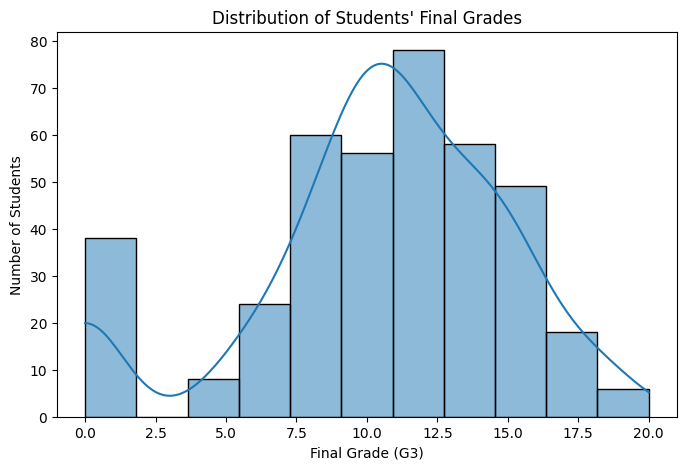

Average final grade: 10.42
Highest final grade: 20
Lowest final grade: 0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 3: Explore the final grade (G3)

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=11, kde=True)

plt.title("Distribution of Students' Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

print("Average final grade:", round(df["G3"].mean(), 2))
print("Highest final grade:", df["G3"].max())
print("Lowest final grade:", df["G3"].min())

Pass/fail counts:
Pass
0    130
1    265
Name: count, dtype: int64

Pass/fail percentages:
Pass
1    67.09
0    32.91
Name: proportion, dtype: float64


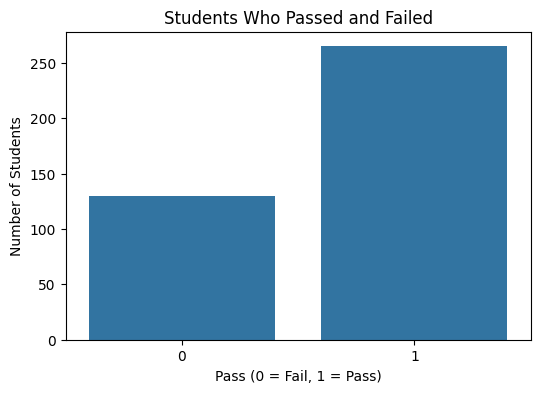

In [ ]:
# Step 4: Create the Pass target

df["Pass"] = (df["G3"] >= 10).astype(int)

print("Pass/fail counts:")
print(df["Pass"].value_counts().sort_index())

print("\nPass/fail percentages:")
print((df["Pass"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Pass")

plt.title("Students Who Passed and Failed")
plt.xlabel("Pass (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.show()


In [ ]:
from google.colab import files
# Corrected spelling typo from CSI643Asignment.py to CSI643Assignment.py
try:
    files.download("CSI643Assignment.py")
except FileNotFoundError:
    print("Error: CSI643Assignment.py not found. Please make sure you have successfully exported your notebook to a Python script first.")

Error: CSI643Assignment.py not found. Please make sure you have successfully exported your notebook to a Python script first.


In [ ]:
# Step 5: Classification models

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, classification_report
)

def make_preprocessor(X, scale_numeric=True):
    numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])


# C1: Early prediction; exclude G1, G2 and G3
# C2: Grade-aware prediction; allow G1 and G2, exclude G3
X_C1 = df.drop(columns=["G1", "G2", "G3", "Pass"])
X_C2 = df.drop(columns=["G3", "Pass"])
y_class = df["Pass"]

# Use the same test split for a fair comparison
X1_train, X1_test, y_train, y_test = train_test_split(
    X_C1, y_class, test_size=0.20, random_state=42, stratify=y_class
)

X2_train, X2_test, _, _ = train_test_split(
    X_C2, y_class, test_size=0.20, random_state=42, stratify=y_class
)

classification_models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.1, 1, 10]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 5]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "model__n_estimators": [100],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3]
        }
    )
}

cv_class = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classification_results = []
best_classification_models = {}

for task_name, X_train, X_test in [
    ("C1 Early", X1_train, X1_test),
    ("C2 Grade-aware", X2_train, X2_test)
]:
    for model_name, (model, params) in classification_models.items():
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(X_train)),
            ("model", model)
        ])

        search = GridSearchCV(
            pipeline,
            param_grid=params,
            cv=cv_class,
            scoring="f1",
            n_jobs=-1
        )

        search.fit(X_train, y_train)
        predictions = search.predict(X_test)

        # ROC-AUC needs prediction probabilities
        probabilities = search.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)

        classification_results.append({
            "Task": task_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
            "ROC-AUC": auc,
            "Best CV F1": search.best_score_,
            "Best Parameters": search.best_params_
        })

        best_classification_models[(task_name, model_name)] = search.best_estimator_

        print(f"\n{task_name} - {model_name}")
        print("Confusion matrix:")
        print(confusion_matrix(y_test, predictions))
        print(classification_report(y_test, predictions, zero_division=0))

classification_table = pd.DataFrame(classification_results)
display(
    classification_table.sort_values(
        ["Task", "F1"], ascending=[True, False]
    ).round(3)
)


C1 Early - Logistic Regression
Confusion matrix:
[[ 9 17]
 [ 8 45]]
              precision    recall  f1-score   support

           0       0.53      0.35      0.42        26
           1       0.73      0.85      0.78        53

    accuracy                           0.68        79
   macro avg       0.63      0.60      0.60        79
weighted avg       0.66      0.68      0.66        79


C1 Early - Decision Tree
Confusion matrix:
[[ 7 19]
 [ 7 46]]
              precision    recall  f1-score   support

           0       0.50      0.27      0.35        26
           1       0.71      0.87      0.78        53

    accuracy                           0.67        79
   macro avg       0.60      0.57      0.56        79
weighted avg       0.64      0.67      0.64        79


C1 Early - Random Forest
Confusion matrix:
[[ 2 24]
 [ 3 50]]
              precision    recall  f1-score   support

           0       0.40      0.08      0.13        26
           1       0.68      0.94      0.7

,Task,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Best CV F1,Best Parameters
2,C1 Early,Random Forest,0.658,0.676,0.943,0.787,0.674,0.812,"{'model__max_depth': 10, 'model__min_samples_l..."
0,C1 Early,Logistic Regression,0.684,0.726,0.849,0.783,0.618,0.793,{'model__C': 0.1}
1,C1 Early,Decision Tree,0.671,0.708,0.868,0.780,0.623,0.778,"{'model__max_depth': 5, 'model__min_samples_le..."
4,C2 Grade-aware,Decision Tree,0.886,0.978,0.849,0.909,0.914,0.942,"{'model__max_depth': None, 'model__min_samples..."
3,C2 Grade-aware,Logistic Regression,0.873,0.957,0.849,0.900,0.946,0.941,{'model__C': 10}
5,C2 Grade-aware,Random Forest,0.861,0.938,0.849,0.891,0.938,0.939,"{'model__max_depth': 10, 'model__min_samples_l..."


In [ ]:
# Step 6: Regression models

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_R1 = df.drop(columns=["G1", "G2", "G3", "Pass"])
X_R2 = df.drop(columns=["G3", "Pass"])
y_reg = df["G3"]

XR1_train, XR1_test, yr_train, yr_test = train_test_split(
    X_R1, y_reg, test_size=0.20, random_state=42
)

XR2_train, XR2_test, _, _ = train_test_split(
    X_R2, y_reg, test_size=0.20, random_state=42
)

regression_models = {
    "Linear Regression": (
        LinearRegression(),
        {}
    ),
    "Decision Tree Regressor": (
        DecisionTreeRegressor(random_state=42),
        {
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 5]
        }
    ),
    "Random Forest Regressor": (
        RandomForestRegressor(random_state=42, n_jobs=-1),
        {
            "model__n_estimators": [100],
            "model__max_depth": [None, 10],
            "model__min_samples_leaf": [1, 3]
        }
    )
}

cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
regression_results = []
best_regression_models = {}

for task_name, X_train, X_test in [
    ("R1 Early", XR1_train, XR1_test),
    ("R2 Grade-aware", XR2_train, XR2_test)
]:
    for model_name, (model, params) in regression_models.items():
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(X_train)),
            ("model", model)
        ])

        search = GridSearchCV(
            pipeline,
            param_grid=params,
            cv=cv_reg,
            scoring="neg_mean_absolute_error",
            n_jobs=-1
        )

        search.fit(X_train, yr_train)
        predictions = search.predict(X_test)

        rmse = np.sqrt(mean_squared_error(yr_test, predictions))

        regression_results.append({
            "Task": task_name,
            "Model": model_name,
            "MAE": mean_absolute_error(yr_test, predictions),
            "RMSE": rmse,
            "R2": r2_score(yr_test, predictions),
            "Best CV MAE": -search.best_score_,
            "Best Parameters": search.best_params_
        })

        best_regression_models[(task_name, model_name)] = search.best_estimator_

        print(f"\n{task_name} - {model_name}")
        print("MAE:", round(mean_absolute_error(yr_test, predictions), 3))
        print("RMSE:", round(rmse, 3))
        print("R²:", round(r2_score(yr_test, predictions), 3))

regression_table = pd.DataFrame(regression_results)
display(
    regression_table.sort_values(
        ["Task", "MAE"], ascending=[True, True]
    ).round(3)
)


R1 Early - Linear Regression
MAE: 3.395
RMSE: 4.196
R²: 0.141

R1 Early - Decision Tree Regressor
MAE: 3.511
RMSE: 4.485
R²: 0.019

R1 Early - Random Forest Regressor
MAE: 3.002
RMSE: 3.769
R²: 0.307

R2 Grade-aware - Linear Regression
MAE: 1.647
RMSE: 2.378
R²: 0.724

R2 Grade-aware - Decision Tree Regressor
MAE: 1.413
RMSE: 2.462
R²: 0.704

R2 Grade-aware - Random Forest Regressor
MAE: 1.191
RMSE: 2.026
R²: 0.8


,Task,Model,MAE,RMSE,R2,Best CV MAE,Best Parameters
2,R1 Early,Random Forest Regressor,3.002,3.769,0.307,2.963,"{'model__max_depth': None, 'model__min_samples..."
0,R1 Early,Linear Regression,3.395,4.196,0.141,3.523,{}
1,R1 Early,Decision Tree Regressor,3.511,4.485,0.019,3.202,"{'model__max_depth': 5, 'model__min_samples_le..."
5,R2 Grade-aware,Random Forest Regressor,1.191,2.026,0.800,0.948,"{'model__max_depth': 10, 'model__min_samples_l..."
4,R2 Grade-aware,Decision Tree Regressor,1.413,2.462,0.704,1.014,"{'model__max_depth': 5, 'model__min_samples_le..."
3,R2 Grade-aware,Linear Regression,1.647,2.378,0.724,1.393,{}


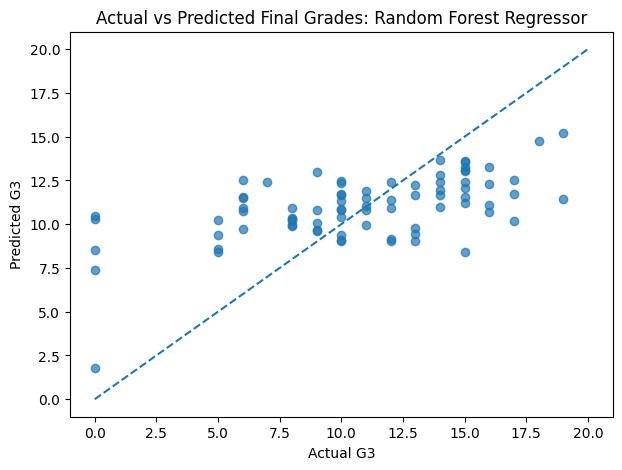

Best R1 model: Random Forest Regressor


In [ ]:

# Step 7: Diagnostic plot for the best R1 model

best_r1_row = (
    regression_table[regression_table["Task"] == "R1 Early"]
    .sort_values("MAE")
    .iloc[0]
)

best_r1_name = best_r1_row["Model"]
best_r1_model = best_regression_models[("R1 Early", best_r1_name)]

predicted_grades = best_r1_model.predict(XR1_test)

plt.figure(figsize=(7, 5))
plt.scatter(yr_test, predicted_grades, alpha=0.7)

# Reference line: perfect predictions
plt.plot([0, 20], [0, 20], linestyle="--")

plt.title(f"Actual vs Predicted Final Grades: {best_r1_name}")
plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.show()

print("Best R1 model:", best_r1_name)


In [ ]:

# Step 8: Save results tables

classification_table.to_csv("classification_results.csv", index=False)
regression_table.to_csv("regression_results.csv", index=False)

print("Saved classification_results.csv")
print("Saved regression_results.csv")

# Download results to your computer
from google.colab import files

files.download("classification_results.csv")
files.download("regression_results.csv")


Saved classification_results.csv
Saved regression_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!jupyter nbconvert --to script CSI643Asignment.ipynb

[NbConvertApp] WARNING | pattern 'CSI643Asignment.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute

In [2]:
!ls -la

total 16
drwxr-xr-x 1 root root 4096 Oct 26 22:18 .
drwxr-xr-x 1 root root 4096 Oct 29 02:59 ..
drwxr-xr-x 4 root root 4096 Oct 26 22:18 .config
drwxr-xr-x 1 root root 4096 Oct 26 22:18 sample_data
